# Outline: DataFrames
- reading in data
- extracting values
  - extracting by number (like Excel, but uncommon)
  - boolean expressions - for subsets of data
  - whole rows
  - whole columns
- dataframes and np.arrays
- Some fiddly things about dataframes
- Some useful dataframe functions
  - head()
  - tail()
  - sort_values()
- Practicing with dataframes
  - compare menus from Starbucks and McDonalds
  - examining data when you first encounter it
  - reasoning about data

### Homework 1

- ### Due **Nov 5 at 1pm**

  <br>
- Do NOT change the variable name for the variable that holds the answer, e.g.

```
weird_numbers = ...
weird_numbers 
```

Do NOT change the variable name 'weird_numbers'. <br>
DO replace the '...' with some code

e.g.
```
weird_numbers = np.array([2,4,6,8])
weird_numbers
```
<br>


- What to do?
  - Find hw1_more_arrays in your vlab Exercises workspace
  - Do this notebook in exactly the same way as other notebooks you have done for exercises
  - Each question counts 1 point
  - There are 16 questions in all
  - Marking is exactly like for your exercises, with one difference...
  - This time, OKpy will not tell you the answer
    - It may give hints if you are NOT close
    - It does not, however, say if the answer is completely correct
  - **Do not leave questions unfilled so they cause an error**
    - marking will stop at that point and all subsequent answers will be wrong
  - If you are unsure, comment out lines that are causing an error so execution continues
    - You will miss that question but not others
  - **Before turning in your notebook, run it from top to bottom to make sure it completes.**
  - **Use "Run > Restart Kernel and Run All Cells"**

### Turning in your homework

- Download your notebook to your computer
  - The notebook is the `more_arrays.ipynb` file
  - When your notebook is open, use: "File > Download"
  - Save `more_arrays.ipynnb` to a location you will remember.
- Upload the notebook to CANVAS

## Today's python topic: Dataframes - some fiddly bits...
- Once you get it they are powerful
- Today the fiddly bits
- Have patience
- Practice...
- Ask questions!

# Dataframes

- Rows and columns of data
- Usually imported from .csv files
- Most common form of publicly available datasets

## Dataframes - The most common destination for imported data


### What is a dataframe? -- example

<img src="dataframe_example.png" align="center" width=1200>

### Dataframe rules

- All columns have the same number of values (UNLIKE Excel)
- A column can only have one **type** of value (int, string float - Again, UNLIKE Excel)
- Columns have names
- Rows can have names.  But row numbers are more common.
- Columns also have numbers
- Rows have numbers
- You can get values by name
- You can get value by number
- Be careful about mixing...

## Pandas - The python package for data frames

Load 'pandas' with the following command at the top of your notebook:

```
import pandas as pd
```

'pd' is the standard abbreviation for pandas, just like 'np' for numpy

# Example for dataframes:  
### QUESTION: Who has more junk food on the menu?  
### McDonalds or Starbucks?
### Read in data.  Put data in a _data frame_

- The pandas function for reading data from a .csv file is:

```
[data frame name] = pd.read_csv("[filename]")
```

- A useful first pandas function and method
  - A **function** has pd.[function name]
  - A **method** has [dataframe_name].[function name]
    - NOTE:  dataframe name, not 'pd' before the '.'
    - e.g. `[data frame name].head()`
      - `my_dataframe.head()`
    - this means run the function `head` on the dataframe `my_dataframe`
  - The method 'head' shows the first few rows of a dataframe
    - e.g. to check that it has been read in OK
    - there is also a `.tail` method if you want to check the last rows in the file

#### Example:

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sb_vs_mac=pd.read_csv("McD_vs_StarB_menus.csv")
sb_vs_mac.head()

,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
0,Starbucks,Chonga Bagel,300,5.0,50,3,12
1,Starbucks,8-Grain Roll,380,6.0,70,7,10
2,Starbucks,Almond Croissant,410,22.0,45,3,10
3,Starbucks,Apple Fritter,460,23.0,56,2,7
4,Starbucks,Banana Nut Bread,420,22.0,52,2,6


#### Notice bold names
- Each column has a name
- Each row has a name
  - Often the row **names** are just the row numbers
  - The can, however, be actual names

In [6]:
### Example dataframe with row names that aren't numbers

my_dataframe = pd.DataFrame({"region" : ['West Midlands', 'Cumbria', 'Yorkshire', 'London'],
                "region_code" : [1,2,3,4],
                "north_south" : ['middle', 'north', 'north', 'south']},
                           index = ['middle', 'north', 'north', 'south'])
my_dataframe

,region,region_code,north_south
middle,West Midlands,1,middle
north,Cumbria,2,north
north,Yorkshire,3,north
south,London,4,south


### Getting values from dataframes

Dataframe values can be looked up in several ways, but there are 4 main ways:
- Get a whole column using the column name: `my_dataframe["region"]`
  - NOTE: We use square brackets to get dataframe values, like arrays
  - This returns the **whole** column
<br>

- Get a single cell (or a few) using row,column **names**
  - `my_dataframe.loc["middle","region"]
  - USE `.loc` for row,column names
<br>

- Get a single cell (or a few) using row,column **numbers**
  - `my_dataframe.iloc[0,0]`
  - USE `.iloc` for row,column numbers
<br>

- Get all rows that match some criteria (e.g. all rows where gender == 'female')
  - We'll do more on this below
  - Uses boolean expressions

In [7]:
my_dataframe["region"]

middle    West Midlands
north           Cumbria
north         Yorkshire
south            London
Name: region, dtype: object

In [9]:
# get a cell value by row, column names
my_dataframe.loc["middle","region"]

north      Cumbria
north    Yorkshire
Name: region, dtype: object

In [10]:
# display the dataframe again
my_dataframe

,region,region_code,north_south
middle,West Midlands,1,middle
north,Cumbria,2,north
north,Yorkshire,3,north
south,London,4,south


In [12]:
# get a cell value by row, column number
my_dataframe.iloc[1,2]

'north'

### Getting a range of values by number
- Use ':'
- [`start`:`end`]
- If `start` is missing start from the beginning
- If `end` is missing finish at the end
- If both are missing get the whole column
  - e.g. [0:10, ...] - rows from 0-9
  - [:10, ...] - rows from 0-9
  - [-3:, ...] - last three rows
  - [100:, ...] - from 100 to the end
  - [1:4, ...] - rows numbered 1, 2 and 3 (2nd to 4th row)

#### Examples

In [19]:
my_dataframe.iloc[0:2,:

,region,region_code,north_south
middle,West Midlands,1,middle
north,Cumbria,2,north


In [21]:
my_dataframe.iloc[0,:]

region         West Midlands
region_code                1
north_south           middle
Name: middle, dtype: object

In [29]:
my_dataframe.iloc[1:4,]

,region,region_code,north_south
north,Cumbria,2,north
north,Yorkshire,3,north
south,London,4,south


In [22]:
my_dataframe.iloc[-2:,:]

,region,region_code,north_south
north,Yorkshire,3,north
south,London,4,south


In [23]:
my_dataframe.iloc[-2:-1,]

,region,region_code,north_south
north,Yorkshire,3,north


#### Back to Starbucks/MacDonalds

- We want to concentrate on fat values
- Get all of the fat values out of the dataframe

In [13]:
# to look at the range of fat values, 
# get values from the 'Fat' column

fat_values = sb_vs_mac["Fat"]
fat_values

0       5.0
1       6.0
2      22.0
3      23.0
4      22.0
       ... 
368    17.0
369    23.0
370    11.0
371    32.0
372    16.0
Name: Fat, Length: 373, dtype: float64

In [14]:
# What is the range of values?
max_fat = np.max(fat_values)
min_fat = np.min(fat_values)
print("range of fat values: ",min_fat," - ",max_fat)

range of fat values:  0.0  -  118.0


#### Distribution of fat values

- max and min tells us where the endpoints are
- which values are most common?
- which values are least common?
- We need to see a distribution

#### Plot the distribution of fat values

(array([165., 133.,  60.,   8.,   4.,   2.,   0.,   0.,   0.,   1.]),
 array([  0. ,  11.8,  23.6,  35.4,  47.2,  59. ,  70.8,  82.6,  94.4,
        106.2, 118. ]),
 <BarContainer object of 10 artists>)

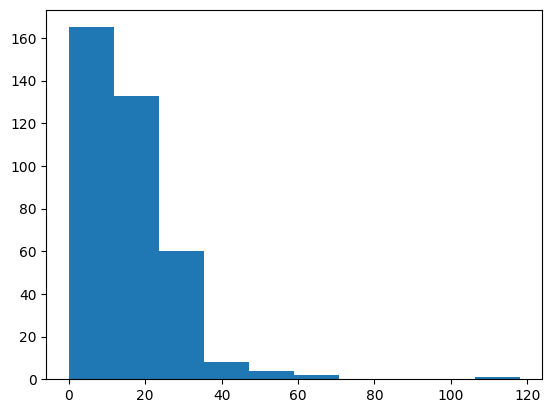

In [15]:
import matplotlib.pyplot as plt

plt.hist(fat_values)

### Important, but temporary, diversion:  Note!
- ```fat_values``` looks and (often) behaves like a np.array
- It is, however, a different type
- Pandas columns are of type `series`
- Sometimes this makes a difference (and sometimes it doesn't)
  - maybe you noticed we used np.max and np.min
  - in those cases numpy treats the series like a numpy array

### How do you tell a 'series' from a numpy array?
#### Compare

In [5]:
fat_values

0       5.0
1       6.0
2      22.0
3      23.0
4      22.0
       ... 
368    17.0
369    23.0
370    11.0
371    32.0
372    16.0
Name: Fat, Length: 373, dtype: float64

### Series values are displayed in a column

#### We can also ask to see the type of the variable

In [16]:
# show me the type of 'fat_values'
type(fat_values)

pandas.core.series.Series

### type is 'Series'

### numpy array version

In [17]:
# convert a column series to a np.array
fat_values_numpy_array = np.array(fat_values)
fat_values_numpy_array[1:10]
# just show the first 10 values

array([ 6., 22., 23., 22., 16., 17., 12., 22., 16.])

#### Notice that these are not in a column anymore
#### and the type is different

In [8]:
type(fat_values_numpy_array)

numpy.ndarray

### type is 'numpy.ndarray' (i.e. a numpy array)
- Often these two types are interchangeable, but...
- Some functions want an array rather than a series
- If you see a message complaining that the input to a function is not an array and mentioning the type 'Series', this could be the issue

### Diversion over.  Back to getting data values from a dataframe


(array([165., 133.,  60.,   8.,   4.,   2.,   0.,   0.,   0.,   1.]),
 array([  0. ,  11.8,  23.6,  35.4,  47.2,  59. ,  70.8,  82.6,  94.4,
        106.2, 118. ]),
 <BarContainer object of 10 artists>)

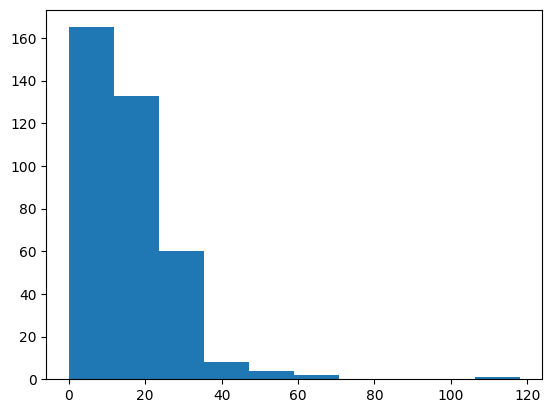

In [38]:
import matplotlib.pyplot as plt

plt.hist(fat_values)

#### What do you notice about the distribution?
Is this what you expected?

#### We might want to look at a subset of values
#### Getting dataframe values in practice

- As we noted above, you _can_ use `.iloc` with row and column numbers, like in a spreadsheet
- The order is always **[row, column]**

#### e.g.

In [27]:
# reminder of the first few lines
sb_vs_mac.head()

,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
0,Starbucks,Chonga Bagel,300,5.0,50,3,12
1,Starbucks,8-Grain Roll,380,6.0,70,7,10
2,Starbucks,Almond Croissant,410,22.0,45,3,10
3,Starbucks,Apple Fritter,460,23.0,56,2,7
4,Starbucks,Banana Nut Bread,420,22.0,52,2,6


In [10]:
# get the value in the first row and first column
sb_vs_mac.iloc[0,0]

'Starbucks'

In [26]:
# get the value in the first row and second column
sb_vs_mac.iloc[0,1]

'Chonga Bagel'

### This is not, however, the most common way of working with dataframe data 

Why? - 2 reasons:
- Data can change
- e.g. columns get added.  Now your numbers all have to be adjusted
- If you access columns by name this is not a problem
- Even if the column changes from 3 to 4, the fat values are still in the column called "Fat"
<br>

- Names are also easier to understand, e.g.
- What values are we getting here?
  - `sb_vs_mac.iloc[:,3]`
  - ????
<br>

-
  - Compare to:
    - `sb_vs_mac["Fat"]`
      - All fat values
    - OR `sb_vs_mac.loc[0,"Fat"]`
      - First item in the fat column
      - If you have sorted from high to low this could be the highest fat item
    - It is clear we are getting "Fat" values
<br>

- NOTICE - we used `.loc[0...` Isn't zero a row number?
  - Yes, but crucially it is also the row name
  - Row names are often numbers
  - There are some 'gotcha's here

##  Selecting rows from a dataframe using a boolean expression: A common operation
- What if we want all high fat items?
- Write a boolean expression that identifies values in one of the columns
  - We will use the column 'Fat' [identified by name]
- Then use the boolean expression to get the corresponding rows

#### E.g.
#### What are the high fat items on each menu?

In [32]:
fat_cutoff = 50
# Our cutoff for very fatty items 
# We want to see all of the rows that have fatty items

boolean_filter = sb_vs_mac["Fat"] > fat_cutoff
# This is my boolean filter.  It will be true whenever a value in the
# fat column is above the cutoff.

# show some boolean filter results
print(boolean_filter[140:150])

#
fatty_stuff = sb_vs_mac[boolean_filter].copy()
# use the boolean filter to get all rows where the filter = True
# .copy() ensures that you have a new dataframe that contains the rows

# You can also do this in one line:
# fatty_stuff = sb_vs_mac[sb_vs_mac["Fat"] > fat_cutoff].copy()
# This is a common way to do this

# fatty_stuff is a subset of the dataframe - a dataframe with 
# just the really high fat items
fatty_stuff

140    False
141     True
142    False
143    False
144     True
145     True
146    False
147    False
148    False
149    False
Name: Fat, dtype: bool


,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
141,McDonalds,Big Breakfast (Large Biscuit),800,52.0,56,4,28
144,McDonalds,Big Breakfast with Hotcakes (Regular Biscuit),1090,56.0,111,6,36
145,McDonalds,Big Breakfast with Hotcakes (Large Biscuit),1150,60.0,116,7,36
194,McDonalds,Chicken McNuggets (20 piece),940,59.0,59,3,44
195,McDonalds,Chicken McNuggets (40 piece),1880,118.0,118,6,87


### Notice how you select rows from the dataframe

```
my_data_frame[(boolean expression)]
```

There is only one entry between [] -- The boolean expression
- Selects _all_ columns in _rows_ where (boolean expression) is true

### Contrast with selecting columns (as above)

When there is a single **column** name between brackets we select a single column


In [9]:
fat_values = fatty_stuff["Fat"].copy()
fat_values

141     52.0
144     56.0
145     60.0
194     59.0
195    118.0
Name: Fat, dtype: float64

In [33]:
# notice the index column, 
# both just above (fat_values) and here (fatty_stuff)

# NOTE the row number in `fatty_stuff` is the row_number from the original data frame
# BE CAREFUL -- this can cause problems -- one of the 'gotcha's with row numbers/names
fatty_stuff

,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
141,McDonalds,Big Breakfast (Large Biscuit),800,52.0,56,4,28
144,McDonalds,Big Breakfast with Hotcakes (Regular Biscuit),1090,56.0,111,6,36
145,McDonalds,Big Breakfast with Hotcakes (Large Biscuit),1150,60.0,116,7,36
194,McDonalds,Chicken McNuggets (20 piece),940,59.0,59,3,44
195,McDonalds,Chicken McNuggets (40 piece),1880,118.0,118,6,87


### Note!!!! - index values in pandas
- The first item has an index (row name) of 141
- Why?
- It was in the 141st position in the **original** dataframe
- The index carries over unless we reset it

### What if we want to see the first item?

In [21]:
fatty_stuff.loc[0,:]
# produces an error

KeyError: 0

In [35]:
# Error was from using .loc instead of .iloc
# There was no row name 0, but there is a row number 0

# first item index is 141 -- Not obvious what this
# number will be unless you know it already
fatty_stuff.iloc[0,:]
# no error this time, but not a great solution since we have to know 141

Restaurant                        McDonalds
Menu_Item     Big Breakfast (Large Biscuit)
Calories                                800
Fat                                    52.0
Carbs                                    56
Fiber                                     4
Protein                                  28
Name: 141, dtype: object

### Solution?  re-make the index so you can use .loc with row numbers

In [36]:
fatty_stuff.reset_index(inplace=True)
fatty_stuff

,index,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
0,141,McDonalds,Big Breakfast (Large Biscuit),800,52.0,56,4,28
1,144,McDonalds,Big Breakfast with Hotcakes (Regular Biscuit),1090,56.0,111,6,36
2,145,McDonalds,Big Breakfast with Hotcakes (Large Biscuit),1150,60.0,116,7,36
3,194,McDonalds,Chicken McNuggets (20 piece),940,59.0,59,3,44
4,195,McDonalds,Chicken McNuggets (40 piece),1880,118.0,118,6,87


### Get first item now

In [37]:
fatty_stuff.loc[0,:]

index                                   141
Restaurant                        McDonalds
Menu_Item     Big Breakfast (Large Biscuit)
Calories                                800
Fat                                    52.0
Carbs                                    56
Fiber                                     4
Protein                                  28
Name: 0, dtype: object

In [29]:
fatty_stuff.loc[0:5,"Calories":"Carbs"]

,Calories,Fat,Carbs
0,800,52.0,56
1,1090,56.0,111
2,1150,60.0,116
3,940,59.0,59
4,1880,118.0,118


### Remember: colon by itself is a special case -- 'get all'

In [20]:
fatty_stuff.loc[0,:] # get all columns 
# (don't need to know start/end names)

index                                   141
Restaurant                        McDonalds
Menu_Item     Big Breakfast (Large Biscuit)
Calories                                800
Fat                                    52.0
Carbs                                    56
Fiber                                     4
Protein                                  28
Name: 0, dtype: object

## NOTE: always use 'copy()' when you extract a subset of values from a dataframe

Do use:
```
fatty_stuff = sb_vs_mac[sb_vs_mac["Fat"] > fat_cutoff].copy()
```
<br>  

Do NOT use (without .copy()):
```
fatty_stuff = sb_vs_mac[sb_vs_mac["Fat"] > fat_cutoff]
```

### Why?
- **Sometimes** (but not always) if you change values in 'fatty_stuff' (a selection from a dataframe)
- you also change values in the original dataframe ('sb_vs_mac')
- That can lead to confusion and difficult errors

## Some other useful dataframe functions

### Remember head() - there is also a tail() function -- check your data after reading!

- ```sb_vs_mac.head()``` shows some initial rows
- ```sb_vs_mac.tail()``` shows some final rows

In [11]:
sb_vs_mac.head()

,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
0,Starbucks,Chonga Bagel,300,5.0,50,3,12
1,Starbucks,8-Grain Roll,380,6.0,70,7,10
2,Starbucks,Almond Croissant,410,22.0,45,3,10
3,Starbucks,Apple Fritter,460,23.0,56,2,7
4,Starbucks,Banana Nut Bread,420,22.0,52,2,6


In [12]:
sb_vs_mac.tail()

,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
368,McDonalds,McFlurry with Oreo Cookies (Small),510,17.0,80,1,12
369,McDonalds,McFlurry with Oreo Cookies (Medium),690,23.0,106,1,15
370,McDonalds,McFlurry with Oreo Cookies (Snack),340,11.0,53,1,8
371,McDonalds,McFlurry with Reese's Peanut Butter Cups (Medium),810,32.0,114,2,21
372,McDonalds,McFlurry with Reese's Peanut Butter Cups (Snack),410,16.0,57,1,10


### List the column names

`sb_vs_mac.columns`

In [31]:
column_names = sb_vs_mac.columns
column_names

Index(['Restaurant', 'Menu_Item', 'Calories', 'Fat', 'Carbs', 'Fiber',
       'Protein'],
      dtype='object')

#### Back to our distribution...

(array([165., 133.,  60.,   8.,   4.,   2.,   0.,   0.,   0.,   1.]),
 array([  0. ,  11.8,  23.6,  35.4,  47.2,  59. ,  70.8,  82.6,  94.4,
        106.2, 118. ]),
 <BarContainer object of 10 artists>)

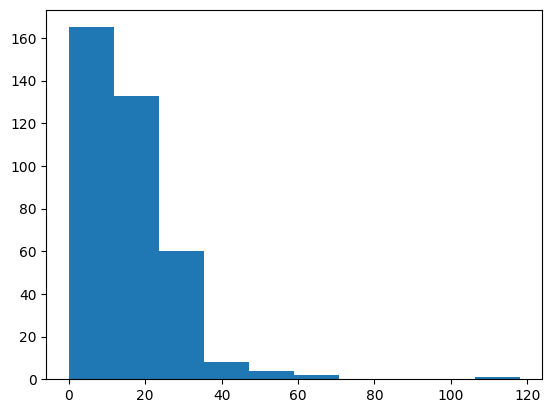

In [39]:
plt.hist(fat_values)

#### What is that really high fat item out on the end? (around 115?)

### Sorting a dataframe - a common operation

In [41]:
# You can sort a whole dataframe using the values in one column

highest_fat = sb_vs_mac.sort_values('Fat',ascending=False).copy()
highest_fat.head()
# sorts the whole dataframe by the calorie column

,Restaurant,Menu_Item,Calories,Fat,Carbs,Fiber,Protein
195,McDonalds,Chicken McNuggets (40 piece),1880,118.0,118,6,87
145,McDonalds,Big Breakfast with Hotcakes (Large Biscuit),1150,60.0,116,7,36
194,McDonalds,Chicken McNuggets (20 piece),940,59.0,59,3,44
144,McDonalds,Big Breakfast with Hotcakes (Regular Biscuit),1090,56.0,111,6,36
141,McDonalds,Big Breakfast (Large Biscuit),800,52.0,56,4,28


#### you can also sort just one column after you have extracted it

In [44]:
orig_fat_values = sb_vs_mac['Fat'].copy()
orig_fat_values

0       5.0
1       6.0
2      22.0
3      23.0
4      22.0
       ... 
368    17.0
369    23.0
370    11.0
371    32.0
372    16.0
Name: Fat, Length: 373, dtype: float64

In [45]:
sorted_fat = orig_fat_values.sort_values(ascending = False)
sorted_fat[0:10]

195    118.0
145     60.0
194     59.0
144     56.0
141     52.0
147     50.0
140     48.0
146     46.0
160     43.0
143     41.0
Name: Fat, dtype: float64

### Exercises - some things to try with dataframes


Extract all of the McDonalds values for one category
- Try Fat.  Then you could try Calories, Carbs, Fiber, Protein
- Plot the distribution for the McDonalds values
<br>

Extract all of the Starbucks values for the same category
- Plot the distribution for the Starbucks values
<br>

Trickier - Plot both Starbucks and McDonalds on the same plot
- Beware of scale differences (How many items are on each menu)
  - you might want to experiment with the "density=True/False" option
- How do you have bars on top of each other (but seethrough) vs bars next to each other
  - you might want to try 
```
plt.hist(Starbucks["Fat"])
plt.hist(McDonalds["Fat"])
```
vs
```
plt.hist([Starbucks["Fat"],McDonalds["Fat"]])
```
   - Also look at the "alpha" option for see-through bars
   

Which fast food provider has higher values?
- Does the shape of the distribution have things that are important to notice?

Harder:  Does one menu have significantly higher fat than the other?
- We will work on this type of problem
- You might start to think about how to do it
- We use the method that John Rauser used for mosquitoes and beer in the early video